# Détection d'anomalies routières : augmentation des données
Suite de **DataViz.ipynb**. On supprime les classes trop petites (vehicle, tires), puis on crée de nouvelles images
(rotation ±15° et luminosité) pour avoir **1000 images avec 3 classes équilibrées**.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageEnhance

DOSSIER = r"C:\Users\MSI\Desktop\RoadAnomaly"
if not os.path.isdir(os.path.join(DOSSIER, "frames")):
    DOSSIER = os.path.join(DOSSIER, "RoadAnomaly")
FRAMES = os.path.join(DOSSIER, "frames")
SORTIE = os.path.join(FRAMES, "DataAugmentation")
os.makedirs(SORTIE, exist_ok=True)

def charger(nom, dossier=FRAMES):
    img = np.array(Image.open(f"{dossier}/{nom}.webp").convert("RGB"))
    masque = np.array(Image.open(f"{dossier}/{nom}.labels/labels_semantic.png")) == 2
    return img, masque

noms = sorted(f[:-5] for f in os.listdir(FRAMES) if f.endswith(".webp"))
df = pd.DataFrame({"nom": noms})
df["type"] = df["nom"].str.split("_").str[0].str.rstrip("0123456789").replace("lost", "tires")
print(len(df), "images")
print("Dossier de sortie :", SORTIE)

60 images
Dossier de sortie : C:\Users\MSI\Desktop\RoadAnomaly\frames\DataAugmentation


## 1. Supprimer vehicle et tires

In [2]:
df = df[~df["type"].isin(["vehicle", "tires"])].reset_index(drop=True)
df["type"].value_counts()

type
animals      31
obstacles    15
cones         8
Name: count, dtype: int64

**Résultat :** il reste 54 images : 31 animals, 15 obstacles, 8 cones. Les 6 images vehicle / tires sont retirées (trop peu d'exemples).

## 2. Combien d'images créer par classe ?

In [3]:
TOTAL = 1000
classes = ["animals", "obstacles", "cones"]
objectif = {c: TOTAL // 3 + (i < TOTAL % 3) for i, c in enumerate(classes)}   # 334, 333, 333
plan = pd.DataFrame({"originales": df["type"].value_counts()[classes], "objectif": pd.Series(objectif)})
plan["à créer"] = plan["objectif"] - plan["originales"]
plan

,originales,objectif,à créer
animals,31,334,303
obstacles,15,333,318
cones,8,333,325


**Résultat :** chaque classe aura environ 333 images. Les cônes (8 originales) ont besoin de beaucoup plus de nouvelles images (≈ 40 par photo) que les animaux (≈ 10 par photo).

## 3. Fonction d'augmentation : rotation ±15° + luminosité

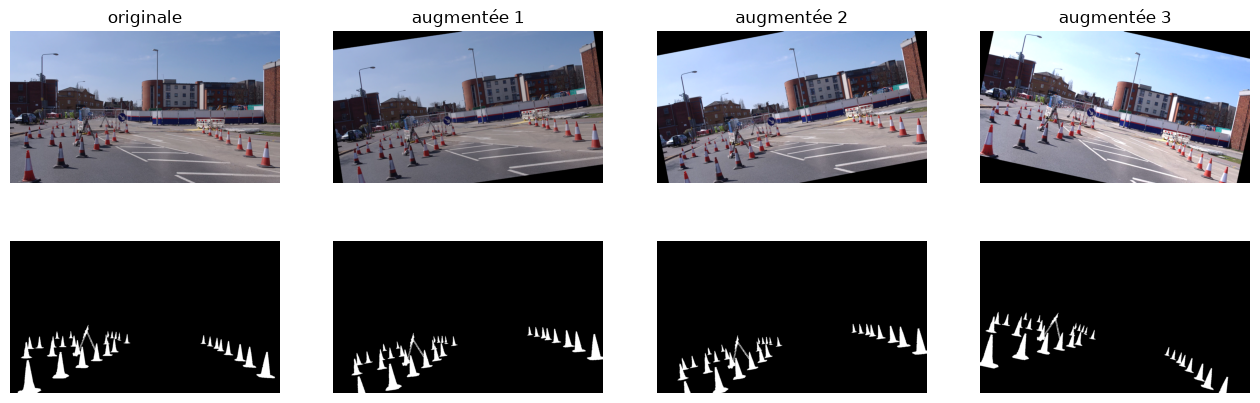

In [4]:
rng = np.random.default_rng(42)

def augmenter(img, masque):
    angle = rng.uniform(-15, 15)                                    # rotation entre -15° et +15°
    img = img.rotate(angle, Image.BILINEAR)
    masque = masque.rotate(angle, Image.NEAREST)                    # même angle pour le masque
    img = ImageEnhance.Brightness(img).enhance(rng.uniform(0.6, 1.4))   # plus sombre / plus clair
    return img, masque

nom = df[df.type == "cones"].nom.iloc[0]
img = Image.open(f"{FRAMES}/{nom}.webp").convert("RGB")
masque = Image.open(f"{FRAMES}/{nom}.labels/labels_semantic.png")
fig, ax = plt.subplots(2, 4, figsize=(16, 5))
for j in range(4):
    a, m = (img, masque) if j == 0 else augmenter(img, masque)
    ax[0, j].imshow(a); ax[1, j].imshow(np.array(m) == 2, cmap="gray")
    ax[0, j].set_title("originale" if j == 0 else f"augmentée {j}")
    ax[0, j].axis("off"); ax[1, j].axis("off")
plt.show()

**Résultat :** l'image tourne et change de luminosité. Le masque tourne **exactement du même angle**, il reste donc bien aligné sur l'objet. On utilise `NEAREST` pour garder un masque propre (0 ou 2), et la luminosité ne touche pas le masque.

## 4. Génération des 1000 images dans `frames/DataAugmentation`

In [5]:
def sauver(img, masque, nom):
    img.save(f"{SORTIE}/{nom}.webp", quality=95)
    os.makedirs(f"{SORTIE}/{nom}.labels", exist_ok=True)
    masque.save(f"{SORTIE}/{nom}.labels/labels_semantic.png")

lignes = []
for c in classes:
    groupe = df[df.type == c].nom.tolist()
    n_aug = [plan.loc[c, "à créer"] // len(groupe) + (i < plan.loc[c, "à créer"] % len(groupe)) for i in range(len(groupe))]
    for nom, k in zip(groupe, n_aug):
        img = Image.open(f"{FRAMES}/{nom}.webp").convert("RGB")
        masque = Image.open(f"{FRAMES}/{nom}.labels/labels_semantic.png")
        sauver(img, masque, f"{nom}_aug00")                            # l'originale
        lignes.append({"nom": f"{nom}_aug00", "classe": c, "source": nom})
        for j in range(1, k + 1):                                      # les nouvelles
            sauver(*augmenter(img, masque), f"{nom}_aug{j:02d}")
            lignes.append({"nom": f"{nom}_aug{j:02d}", "classe": c, "source": nom})

aug = pd.DataFrame(lignes)
aug.to_csv(f"{SORTIE}/etiquettes.csv", index=False)
print(len(aug), "images dans", SORTIE)

1000 images dans C:\Users\MSI\Desktop\RoadAnomaly\frames\DataAugmentation


**Résultat :** 1000 images (54 originales + 946 nouvelles) sont créées. Elles gardent le même format que `frames` (`nom.webp` + `nom.labels/labels_semantic.png`), et `etiquettes.csv` donne la classe et l'image d'origine de chacune.

## 5. Vérification : classes équilibrées ?

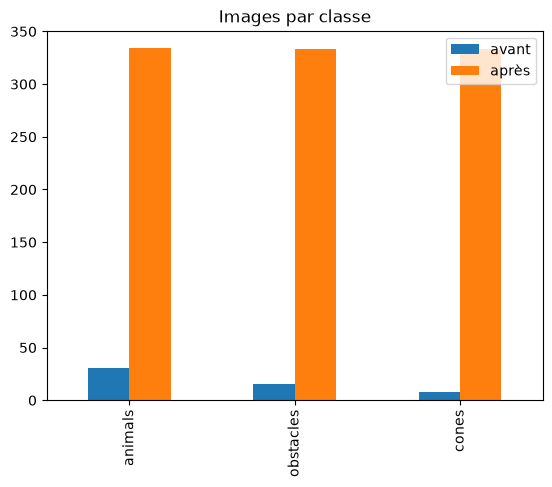

In [6]:
pd.DataFrame({"avant": df["type"].value_counts()[classes],
              "après": aug["classe"].value_counts()[classes]}).plot.bar(title="Images par classe")
plt.show()

**Résultat :** avant, 31 / 15 / 8 images. Après, 334 / 333 / 333 : les 3 classes sont équilibrées.

## 6. Exemples d'images augmentées

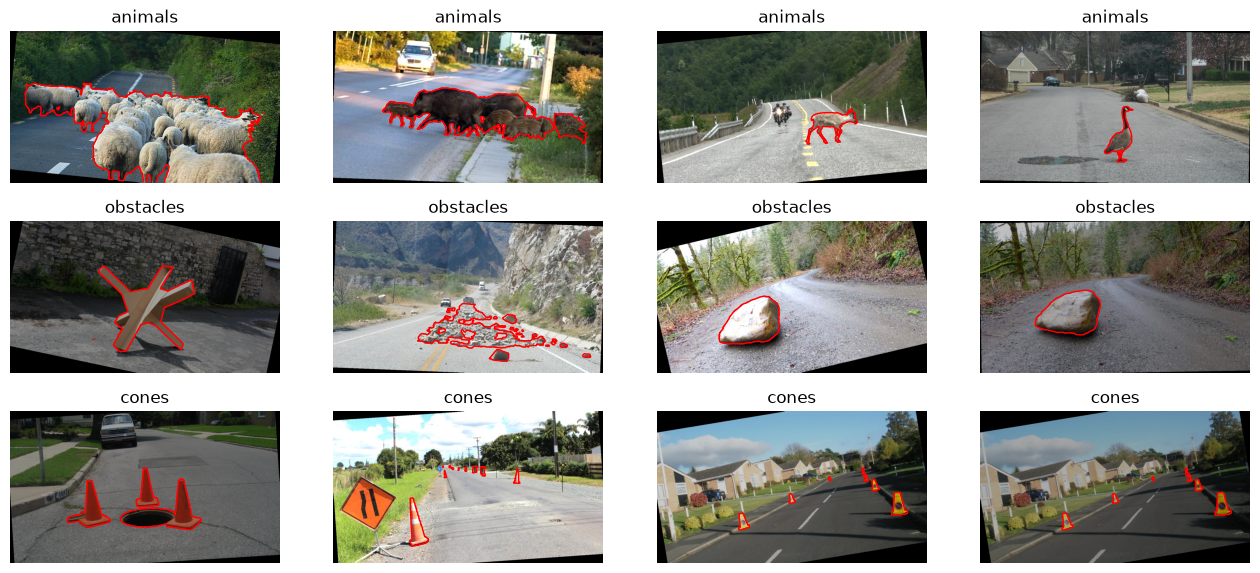

In [7]:
fig, ax = plt.subplots(3, 4, figsize=(16, 7))
for i, c in enumerate(classes):
    for j, nom in enumerate(aug[aug.classe == c].sample(4, random_state=1).nom):
        img, m = charger(nom, SORTIE)
        ax[i, j].imshow(img); ax[i, j].contour(m, colors="red", linewidths=1)
        ax[i, j].set_title(c); ax[i, j].axis("off")
plt.show()

**Résultat :** le contour rouge (masque) suit toujours l'objet après rotation et changement de luminosité. Les coins noirs viennent de la rotation, ils sont marqués comme fond.

## 7. Le problème des 10 % de pixels anomalie
L'augmentation équilibre les **images**, mais pas les **pixels** : dans chaque image, il y a toujours beaucoup plus de route que d'anomalie.

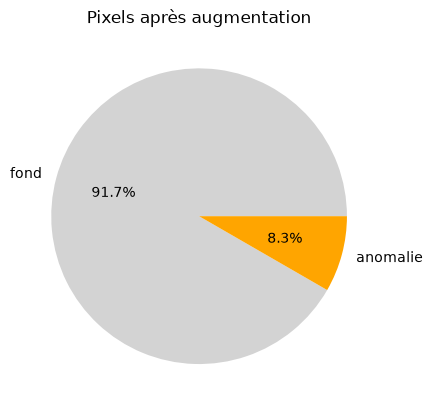

In [8]:
aug["anomalie_%"] = [charger(n, SORTIE)[1].mean() * 100 for n in aug.nom]
p = aug["anomalie_%"].mean()
plt.pie([100 - p, p], labels=["fond", "anomalie"], autopct="%.1f%%", colors=["lightgray", "orange"])
plt.title("Pixels après augmentation")
plt.show()

**Résultat :** la part de pixels anomalie reste faible. Un modèle qui répond « fond » partout aurait déjà une très bonne précision… sans rien détecter.

### Preuve : la précision ne suffit pas

In [9]:
img, vrai = charger(aug.nom.iloc[0], SORTIE)
pred = np.zeros_like(vrai)                         # modèle « paresseux » : aucun pixel anomalie

precision = (pred == vrai).mean()
dice = 2 * (pred & vrai).sum() / (pred.sum() + vrai.sum())
print(f"Précision : {precision:.0%}   Dice : {dice:.0%}")

Précision : 93%   Dice : 0%


**Résultat :** le modèle paresseux a une précision très élevée mais un **Dice de 0 %**. Il faut donc entraîner et mesurer avec Dice / IoU, pas avec la précision.

### Solution 2 : perte Dice + Focal pour l'entraînement
- **Dice** : mesure le recouvrement entre la prédiction et le masque. Elle ne dépend pas du nombre de pixels de fond.
- **Focal** : diminue le poids des pixels faciles (la route) pour se concentrer sur les pixels difficiles (les bords de l'objet).
- On additionne les deux : `perte = Dice + Focal`.

Code à utiliser dans le notebook d'entraînement (PyTorch) :
```python
import torch, torch.nn.functional as F

def dice_focal(logits, masque, alpha=0.75, gamma=2):
    prob = torch.sigmoid(logits)
    dice = 1 - (2 * (prob * masque).sum() + 1) / (prob.sum() + masque.sum() + 1)
    bce = F.binary_cross_entropy_with_logits(logits, masque, reduction="none")
    pt = torch.exp(-bce)
    a = alpha * masque + (1 - alpha) * (1 - masque)   # alpha > 0.5 : plus de poids aux anomalies
    focal = (a * (1 - pt) ** gamma * bce).mean()
    return dice + focal
```

**Résultat :** avec poids + Dice + Focal, le modèle ne peut plus « tricher » en prédisant seulement du fond. On mesurera le modèle avec l'**IoU** et le **Dice** de la classe anomalie.

## Conclusion
- vehicle et tires supprimés → 3 classes : animals, obstacles, cones
- Augmentation avec seulement **rotation ±15°** et **luminosité**, masque tourné du même angle
- **1000 images** dans `frames/DataAugmentation` : 334 animals, 333 obstacles, 333 cones → **classes équilibrées**
- 10 % de pixels anomalie → **poids des classes** + perte **Dice + Focal**, mesure avec **IoU / Dice**
- Attention : les nouvelles images sont des copies modifiées des 54 originales. Pour un test honnête, découper train / test **par image d'origine** (colonne `source` de `etiquettes.csv`), pour qu'une photo et ses copies ne soient jamais à la fois en train et en test.